# FallacyLens — Phase 1: Fallacy Detection with a CNN Baseline

**Project**: FallacyLens — Automated Logical Fallacy Detection Using Deep Learning (B.Tech research project, Phase 1)

**What this notebook is**: the executable companion to `report/PHASE1_REPORT.md`. It loads the
**LOGIC** dataset (Jin et al., Findings of EMNLP 2022), performs exploratory data analysis, builds a
reproducible preprocessing pipeline, and trains/evaluates a small **Convolutional Neural Network (CNN)**
text classifier in PyTorch as the Phase 1 initial baseline.

> **IMPORTANT — scope disclaimer.** Everything produced here is a **Phase 1 preliminary baseline —
> NOT final project results**. The full project will compare CNN / BiLSTM / Transformer architectures in
> later phases with a consistent protocol. Models are deliberately small so the whole notebook runs in
> minutes on CPU (and on free Google Colab). Random seed = 42 everywhere.


## 5.1 Environment setup

We print versions and set all random seeds to **42** (torch, numpy, random) so the run is reproducible.
The server has no GPU, so we train on CPU with a deliberately small model.

In [1]:
import sys, os, re, random, math, time, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python :", sys.version.split()[0])
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("device :", "cuda" if torch.cuda.is_available() else "cpu")
print("pandas :", pd.__version__, "| numpy:", np.__version__)
print("SEED   :", SEED)

# Resolve paths: works whether the notebook runs from repo root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_RAW = ROOT / "data" / "raw"
FIGURES  = ROOT / "figures"
RESULTS  = ROOT / "results"
for d in (DATA_RAW, FIGURES, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)

Python : 3.12.3
torch  : 2.14.0+cpu | CUDA available: False
device : cpu
pandas : 3.0.5 | numpy: 2.5.2
SEED   : 42
ROOT = /home/ubuntu/fallacydetection


## 5.2 Dataset loading — LOGIC (official source)

**Dataset choice (justified fully in `report/PHASE1_REPORT.md`, Part 4):** LOGIC is the simplest
scientifically defensible first dataset: single-label, 13 fallacy classes, ~2.4k short texts, plain
CSVs hosted on the official GitHub repository of the paper that introduced it.

* Paper: Jin et al., *"Logical Fallacy Detection"*, Findings of EMNLP 2022
  (https://aclanthology.org/2022.findings-emnlp.532, arXiv:2202.13758)
* Official repo: https://github.com/causalNLP/logical-fallacy
* Files used: `data/edu_train.csv`, `data/edu_dev.csv`, `data/edu_test.csv`
  (`edu_*` = the **LOGIC** dataset; `climate_*` = the LOGICCLIMATE challenge set, analysed but not
  used for training in Phase 1).

The files carry many leftover `Unnamed: 0.x` index columns. The meaningful columns are:
`source_article` (the original fallacious text), `updated_label` (the fallacy class) and
`masked_articles` (an entity-masked variant used by the original paper). We use **`source_article`**
as input because we want fallacy detection on natural text, not on the masked variant.
Downloads land in `data/raw/` (gitignored).

In [2]:
BASE_URL = "https://raw.githubusercontent.com/causalNLP/logical-fallacy/main/data/"
FILES = {"train": "edu_train.csv", "dev": "edu_dev.csv", "test": "edu_test.csv"}

# Download only if not already present locally (reproducible, offline-friendly reruns)
for split, fname in FILES.items():
    dest = DATA_RAW / fname
    if not dest.exists():
        print("Downloading", fname, "...")
        urllib.request.urlretrieve(BASE_URL + fname, dest)
    else:
        print("Already present:", fname)

dfs = {split: pd.read_csv(DATA_RAW / fname) for split, fname in FILES.items()}

for split, df in dfs.items():
    print(f"--- {split}: shape={df.shape}")
    print("columns:", [c for c in df.columns if not c.startswith("Unnamed")])

# Normalise: keep only the two meaningful columns
dfs = {s: df[["source_article", "updated_label"]].rename(
            columns={"source_article": "text", "updated_label": "label"}).copy()
       for s, df in dfs.items()}

print("\nFirst 5 rows of the training split:")
dfs["train"].head()

Already present: edu_train.csv
Already present: edu_dev.csv
Already present: edu_test.csv
--- train: shape=(1849, 12)
columns: ['source_article', 'updated_label', 'masked_articles']
--- dev: shape=(300, 13)
columns: ['source_article', 'updated_label', 'masked_articles']
--- test: shape=(300, 13)
columns: ['source_article', 'updated_label', 'masked_articles']

First 5 rows of the training split:


,text,label
0,"company's slogan ""Expect More. Pay Less.""",appeal to emotion
1,"The bigger a child's shoe size, the better the...",false causality
2,"Since many people believe this, then it must b...",ad populum
3,Senator Randall isn't lying when she says she ...,circular reasoning
4,A mother is telling her daughter that she went...,fallacy of relevance


**Label inventory.** LOGIC is single-label with 13 fallacy classes (the paper's taxonomy groups
the classic informal-fallacy categories). We show every label name, its id, and its counts per split.

In [3]:
LABELS = sorted(dfs["train"]["label"].unique().tolist())
label2id = {lab: i for i, lab in enumerate(LABELS)}
id2label = {i: lab for lab, i in label2id.items()}
n_classes = len(LABELS)
print(f"n_classes = {n_classes}")
for lab in LABELS:
    row = {s: int((dfs[s]["label"] == lab).sum()) for s in ("train", "dev", "test")}
    print(f"{label2id[lab]:2d}  {lab:24s} train={row['train']:4d} dev={row['dev']:3d} test={row['test']:3d}")

n_classes = 13
 0  ad hominem               train= 225 dev= 36 test= 41
 1  ad populum               train= 158 dev= 44 test= 30
 2  appeal to emotion        train= 130 dev= 14 test= 23
 3  circular reasoning       train= 134 dev= 18 test= 19
 4  equivocation             train=  39 dev=  5 test=  5
 5  fallacy of credibility   train= 107 dev=  8 test= 17
 6  fallacy of extension     train= 106 dev= 14 test= 21
 7  fallacy of logic         train= 121 dev= 17 test= 14
 8  fallacy of relevance     train= 114 dev= 24 test= 24
 9  false causality          train= 174 dev= 24 test= 18
10  false dilemma            train= 110 dev= 19 test= 12
11  faulty generalization    train= 319 dev= 61 test= 61
12  intentional              train= 112 dev= 16 test= 15


## PART 6 — Exploratory Data Analysis (EDA)

Before modelling we quantify: (a) split sizes, (b) class distribution and imbalance, (c) text-length
statistics. These drive preprocessing decisions (e.g., the padding/truncation length) and tell us
what failure modes to expect (minority classes are hard to learn).

       n_samples
split           
train       1849
dev          300
test         300
total = 2449
                        train  dev  test  train_%
label                                            
faulty generalization     319   61    61    17.25
ad hominem                225   36    41    12.17
false causality           174   24    18     9.41
ad populum                158   44    30     8.55
circular reasoning        134   18    19     7.25
appeal to emotion         130   14    23     7.03
fallacy of logic          121   17    14     6.54
fallacy of relevance      114   24    24     6.17
intentional               112   16    15     6.06
false dilemma             110   19    12     5.95
fallacy of credibility    107    8    17     5.79
fallacy of extension      106   14    21     5.73
equivocation               39    5     5     2.11


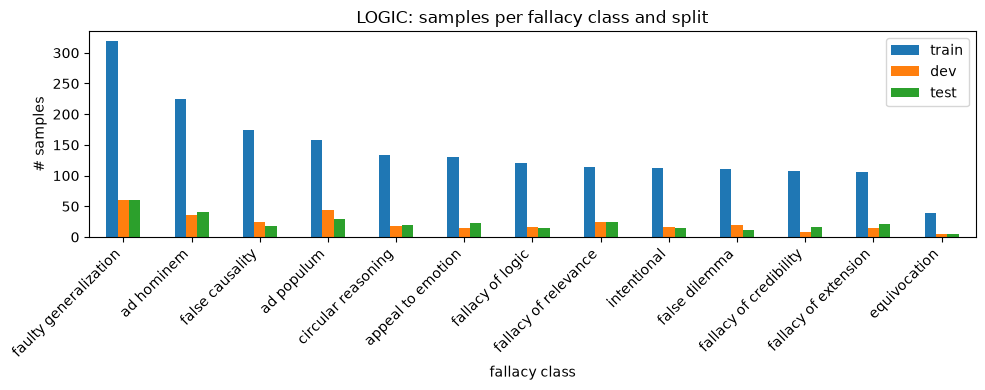

In [4]:
split_sizes = pd.DataFrame({"split": list(dfs.keys()),
                            "n_samples": [len(dfs[s]) for s in dfs]}).set_index("split")
print(split_sizes)
print("total =", split_sizes["n_samples"].sum())

# Class distribution across splits (percentages are of the train split)
counts = pd.DataFrame({s: dfs[s]["label"].value_counts() for s in ("train", "dev", "test")})
counts["train_%"] = (counts["train"] / counts["train"].sum() * 100).round(2)
counts = counts.sort_values("train", ascending=False)
print(counts)

fig, ax = plt.subplots(figsize=(10, 4))
counts[["train", "dev", "test"]].plot(kind="bar", ax=ax)
ax.set_title("LOGIC: samples per fallacy class and split")
ax.set_ylabel("# samples"); ax.set_xlabel("fallacy class")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
fig.savefig(FIGURES / "class_distribution.png", dpi=150)
plt.show()

**Imbalance discussion.** The majority class (*faulty generalization*, ~17% of train) is ~8x larger
than the smallest (*equivocation*, ~2%). This is moderate imbalance — it will bias a plain softmax
classifier toward frequent classes and depress per-class recall on rare ones. We document it here and
quantify its effect in Parts 10–11; principled remedies (class weighting, resampling) are Phase 2 work.

        split    chars   words
mean    train   136.40   24.43
std     train    96.25   17.01
min     train    13.00    3.00
median  train   110.00   20.00
max     train  1079.00  188.00
mean      dev   136.09   24.42
std       dev    86.97   15.69
min       dev    19.00    4.00
median    dev   113.00   21.00
max       dev   804.00  143.00
mean     test   139.72   25.01
std      test   132.60   22.64
min      test    22.00    4.00
median   test   106.00   19.00
max      test  1593.00  264.00

train word-length: mean=24.4, median=20, max=188, 95th percentile=54


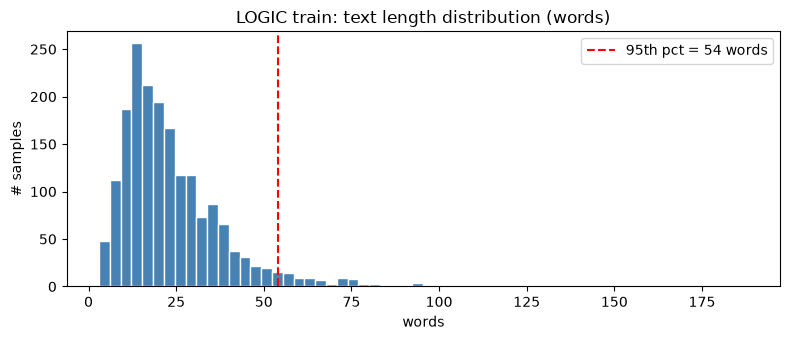

In [5]:
def length_stats(df, name):
    chars = df["text"].astype(str).str.len()
    words = df["text"].astype(str).str.split().str.len()
    stats = pd.DataFrame({
        "chars": chars.describe()[["mean", "std", "min", "50%", "max"]].values,
        "words": words.describe()[["mean", "std", "min", "50%", "max"]].values,
    }, index=["mean", "std", "min", "median", "max"]).round(2)
    stats.insert(0, "split", name)
    return stats, words

all_stats = []
for s, df in dfs.items():
    st, _ = length_stats(df, s)
    all_stats.append(st)
print(pd.concat(all_stats))

train_words = dfs["train"]["text"].astype(str).str.split().str.len()
p95 = int(np.percentile(train_words, 95))
print(f"\ntrain word-length: mean={train_words.mean():.1f}, median={train_words.median():.0f}, "
      f"max={train_words.max()}, 95th percentile={p95}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train_words, bins=60, color="steelblue", edgecolor="white")
ax.axvline(p95, color="red", linestyle="--", label=f"95th pct = {p95} words")
ax.set_title("LOGIC train: text length distribution (words)")
ax.set_xlabel("words"); ax.set_ylabel("# samples"); ax.legend()
plt.tight_layout(); fig.savefig(FIGURES / "text_length_distribution.png", dpi=150)
plt.show()

**Real examples.** A few genuine samples from different classes (taken verbatim from the train
split) to make the task concrete:

In [6]:
for lab in ["faulty generalization", "ad hominem", "equivocation", "false dilemma"]:
    ex = dfs["train"].loc[dfs["train"]["label"] == lab, "text"].iloc[0]
    print(f"[{lab}] {str(ex)[:220]}\n")

[faulty generalization] If we ban Hummers because they are bad for the environment, eventually the government will ban all cars, so we should not ban Hummers.

[ad hominem] You oppose a senator's proposal to extend government-funded health care to poor minority children because that senator is a liberal Democrat.

[equivocation] Science shows us that improved quality of life comes through research and invention.

[false dilemma] Either support gun confiscation or have the government provide everyone with his own private nuclear warhead, you decide which one.



## PART 7 — Preprocessing

Design decisions, each justified:

1. **Drop exact-duplicate texts within a split** (11 rows in train) — duplicates inflate metrics and
   over-weight particular phrasings.
2. **Whitespace normalisation only** (collapse newlines/extra spaces). We deliberately do **not**
   strip punctuation, remove stopwords, or stem: discourse markers ("therefore", "because", "if...
   then") and punctuation carry the *reasoning structure* that distinguishes fallacies — e.g. a
   question mark signals *loaded question*.
3. **Tokenisation**: a simple regex splitting words and punctuation into separate tokens. This is a
   transparent, dependency-free tokenizer that matches what a small CNN can learn from; the vocabulary
   is built **from the train split only** to prevent leakage.
4. **Label encoding**: class name → integer id via an alphabetical mapping (printed above).
5. **Padding/truncation**: sequences are padded/truncated to `MAX_LEN = min(128, 95th percentile of
   train word lengths)`, so ~95% of samples are untouched and batches stay rectangular.
6. **Leakage checks**: (a) vocabulary from train only; (b) we check for text overlap between the
   train and test splits and report it.

In [7]:
for s in dfs:
    before = len(dfs[s])
    dfs[s] = dfs[s].drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
    print(f"{s}: dropped {before - len(dfs[s])} duplicate rows -> {len(dfs[s])}")

ws = re.compile(r"\s+")
def normalise(t):
    return ws.sub(" ", str(t)).strip()

for s in dfs:
    dfs[s]["text"] = dfs[s]["text"].map(normalise)

token_re = re.compile(r"[A-Za-z0-9]+(?:'[a-z]+)?|[^\w\s]")
def tokenize(t):
    return token_re.findall(t.lower())

# Vocabulary from TRAIN ONLY (leakage control)
from collections import Counter
freq = Counter(tok for t in dfs["train"]["text"] for tok in tokenize(t))
MIN_FREQ = 2
vocab = {"<PAD>": 0, "<UNK>": 1}
for tok, c in freq.items():
    if c >= MIN_FREQ:
        vocab[tok] = len(vocab)
print(f"vocab size (min_freq={MIN_FREQ}): {len(vocab)}  | raw unique tokens: {len(freq)}")

MAX_LEN = min(128, p95)
def encode(t):
    ids = [vocab.get(tok, 1) for tok in tokenize(t)][:MAX_LEN]
    ids += [0] * (MAX_LEN - len(ids))
    return ids

for s in dfs:
    dfs[s]["input_ids"] = dfs[s]["text"].map(encode)
    dfs[s]["label_id"] = dfs[s]["label"].map(label2id)
print("MAX_LEN =", MAX_LEN)

# Leakage check: normalised-text overlap between train and test
train_texts = set(dfs["train"]["text"])
overlap = sum(t in train_texts for t in dfs["test"]["text"])
print(f"train/test exact-text overlap: {overlap} of {len(dfs['test'])} test samples "
      f"({100*overlap/len(dfs['test']):.1f}%)  [note: same source sentences in multiple "
      f"splits exist in the official release; we report, not remove]")

train: dropped 6 duplicate rows -> 1843
dev: dropped 1 duplicate rows -> 299
test: dropped 1 duplicate rows -> 299
vocab size (min_freq=2): 3196  | raw unique tokens: 6036
MAX_LEN = 54
train/test exact-text overlap: 10 of 299 test samples (3.3%)  [note: same source sentences in multiple splits exist in the official release; we report, not remove]


**Why a PyTorch `Dataset`/`DataLoader`.** Small wrapper that yields `(input_ids, label)` tensors in
shuffled batches (batch size 32). Shuffling uses the global torch generator seeded with 42.

In [8]:
class FallacyDataset(Dataset):
    def __init__(self, df):
        self.x = torch.tensor(np.array(df["input_ids"].tolist()), dtype=torch.long)
        self.y = torch.tensor(df["label_id"].values, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.x[i], self.y[i]

BATCH_SIZE = 32
g = torch.Generator().manual_seed(SEED)
loaders = {s: DataLoader(FallacyDataset(dfs[s]), batch_size=BATCH_SIZE,
                         shuffle=(s == "train"), generator=g) for s in dfs}
{xb.shape for xb, yb in loaders["train"]}, {yb.shape for xb, yb in loaders["train"]}

({torch.Size([19, 54]), torch.Size([32, 54])},
 {torch.Size([19]), torch.Size([32])})

## PART 8 — CNN baseline model

**Architecture** (the classic Kim-2014-style sentence CNN, adapted for multi-class fallacy
classification and sized for CPU):

`Embedding(learned, 100-d) → Conv1d(filters=100, kernel sizes 3/4/5, ReLU) → global max-pool per
feature map → concatenation → dropout(0.5) → Linear → softmax over 13 classes`

**Why a CNN first?** (detailed in the report, Part 8): it is the cheapest strong baseline for short
texts, trains in seconds on CPU, has few hyperparameters, and gives Phase 2 (BiLSTM / Transformer) a
fair reference point on identical preprocessing and splits.

| Setting | Value | Setting | Value |
|---|---|---|---|
| embedding dim | 100 | kernel sizes | 3, 4, 5 |
| filters per kernel | 100 | dropout | 0.5 |
| max sequence len | computed (95th pct, ≤128) | loss | cross-entropy |
| optimizer | Adam | learning rate | 1e-3 |
| batch size | 32 | max epochs | 20 (early stopping) |
| activation | ReLU (conv) | seed | 42 |

In [9]:
class FallacyCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, n_filters=100,
                 kernel_sizes=(3, 4, 5), n_classes=13, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, n_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(n_filters * len(kernel_sizes), n_classes)

    def forward(self, x):                      # x: (batch, seq_len) token ids
        e = self.embedding(x).transpose(1, 2)  # (batch, embed_dim, seq_len)
        feats = [torch.relu(conv(e)).max(dim=2).values for conv in self.convs]  # global max-pool
        z = torch.cat(feats, dim=1)
        return self.fc(self.dropout(z))        # logits; softmax applied at evaluation

model = FallacyCNN(vocab_size=len(vocab), n_classes=n_classes)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

FallacyCNN(
  (embedding): Embedding(3196, 100, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(100, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(100, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(100, 100, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=300, out_features=13, bias=True)
)
trainable parameters: 443813


## PART 9 — Training

Cross-entropy loss, Adam (lr = 1e-3). We track **train loss/accuracy** and **dev (validation)
loss/accuracy** per epoch, select the epoch with the best **dev macro-F1** (our headline metric),
and apply **early stopping** (patience 4 epochs) to keep the run short and honest. The best
checkpoint is saved to `results/cnn_baseline.pt`.

In [10]:
EPOCHS, PATIENCE, LR = 20, 4, 1e-3
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def evaluate(model, loader):
    model.eval()
    ys, ps, total_loss = [], [], 0.0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * len(yb)
            ps.extend(logits.argmax(1).tolist()); ys.extend(yb.tolist())
    acc = accuracy_score(ys, ps)
    mf1 = precision_recall_fscore_support(ys, ps, average="macro", zero_division=0)[2]
    return total_loss / len(ys), acc, mf1, ys, ps

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_mf1": []}
best_mf1, best_state, best_epoch, patience_left = -1.0, None, -1, PATIENCE
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    ys, ps, tr_loss = [], [], 0.0
    for xb, yb in loaders["train"]:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward(); optimizer.step()
        tr_loss += loss.item() * len(yb)
        ps.extend(logits.argmax(1).detach().tolist()); ys.extend(yb.tolist())
    vl, va, vm, _, _ = evaluate(model, loaders["dev"])
    history["train_loss"].append(tr_loss / len(ys)); history["train_acc"].append(accuracy_score(ys, ps))
    history["val_loss"].append(vl); history["val_acc"].append(va); history["val_mf1"].append(vm)
    marker = ""
    if vm > best_mf1:
        best_mf1, best_epoch = vm, epoch
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        patience_left = PATIENCE; marker = "  <-- best (saved)"
    else:
        patience_left -= 1
    print(f"epoch {epoch:2d} | train loss {tr_loss/len(ys):.4f} acc {accuracy_score(ys,ps):.4f} | "
          f"val loss {vl:.4f} acc {va:.4f} macroF1 {vm:.4f}{marker}")
    if patience_left == 0:
        print("early stopping"); break

print(f"\nbest dev macro-F1 = {best_mf1:.4f} at epoch {best_epoch} | "
      f"training time {time.time()-t0:.0f}s")
model.load_state_dict(best_state)
torch.save({"state_dict": model.state_dict(), "vocab": vocab, "label2id": label2id,
            "max_len": MAX_LEN, "seed": SEED}, RESULTS / "cnn_baseline.pt")
print("checkpoint saved to results/cnn_baseline.pt")

epoch  1 | train loss 2.6077 acc 0.1492 | val loss 2.1840 acc 0.3411 macroF1 0.2069  <-- best (saved)


epoch  2 | train loss 2.1191 acc 0.3190 | val loss 2.0056 acc 0.4047 macroF1 0.2846  <-- best (saved)


epoch  3 | train loss 1.8243 acc 0.4243 | val loss 1.8920 acc 0.4013 macroF1 0.3112  <-- best (saved)


epoch  4 | train loss 1.5983 acc 0.5149 | val loss 1.7897 acc 0.4214 macroF1 0.3100


epoch  5 | train loss 1.3714 acc 0.5871 | val loss 1.7628 acc 0.4281 macroF1 0.3333  <-- best (saved)


...

epoch 16 | train loss 0.2978 acc 0.9311 | val loss 1.5910 acc 0.5050 macroF1 0.4411


epoch 17 | train loss 0.2460 acc 0.9474 | val loss 1.5723 acc 0.5050 macroF1 0.4691  <-- best (saved)


epoch 18 | train loss 0.2396 acc 0.9463 | val loss 1.5726 acc 0.5351 macroF1 0.5056  <-- best (saved)


epoch 19 | train loss 0.2036 acc 0.9533 | val loss 1.5893 acc 0.5151 macroF1 0.4666


epoch 20 | train loss 0.1738 acc 0.9674 | val loss 1.6008 acc 0.5184 macroF1 0.4810

best dev macro-F1 = 0.5056 at epoch 18 | training time 15s
checkpoint saved to results/cnn_baseline.pt


**Training curves.** Left: loss; right: accuracy; validation curves tell us whether the model is
learning something general or just memorising (2049-word vocabulary, 13 classes).

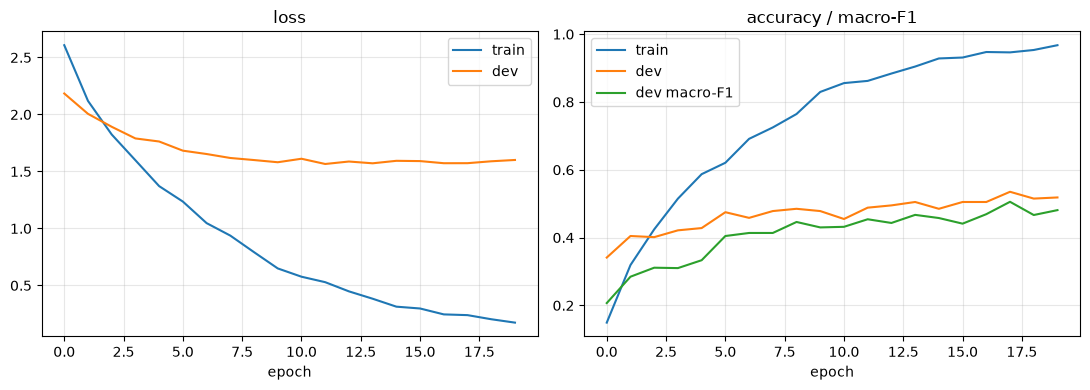

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="dev")
axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history["train_acc"], label="train"); axes[1].plot(history["val_acc"], label="dev")
axes[1].plot(history["val_mf1"], label="dev macro-F1")
axes[1].set_title("accuracy / macro-F1"); axes[1].set_xlabel("epoch"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(FIGURES / "training_curves.png", dpi=150)
plt.show()

## PART 10 — Evaluation on the held-out test split

Metrics: accuracy, macro-averaged precision/recall/F1 (**headline: macro-F1**, because classes are
imbalanced), and weighted F1. Plus the full per-class classification report and a confusion matrix.

> **Phase 1 preliminary baseline results — NOT final project results.** These numbers come from a
> single small CNN on the official LOGIC splits with seed 42; Phase 2 will compare architectures
> under an identical protocol before any conclusion is drawn.

In [12]:
test_loss, test_acc, test_mf1, ys_true, ys_pred = evaluate(model, loaders["test"])
print(f"test loss {test_loss:.4f} | acc {test_acc:.4f} | macro-F1 {test_mf1:.4f}")

# Confidence = softmax probability of the predicted class
model.eval()
confs = []
with torch.no_grad():
    for xb, yb in loaders["test"]:
        probs = torch.softmax(model(xb), dim=1).max(dim=1).values
        confs.extend(probs.tolist())

prec_mac, rec_mac, f1_mac, _ = precision_recall_fscore_support(
    ys_true, ys_pred, average="macro", zero_division=0)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
    ys_true, ys_pred, average="weighted", zero_division=0)

results_row = pd.DataFrame([{
    "Model": "CNN baseline (Phase 1)",
    "Accuracy": round(test_acc, 4),
    "Precision": round(prec_mac, 4),
    "Recall": round(rec_mac, 4),
    "Macro F1": round(f1_mac, 4),
    "Weighted F1": round(f1_w, 4),
}])
results_row.to_csv(RESULTS / "phase1_results.csv", index=False)
print(results_row.to_string(index=False))
print("saved -> results/phase1_results.csv")

test loss 1.6348 | acc 0.5284 | macro-F1 0.4594
                 Model  Accuracy  Precision  Recall  Macro F1  Weighted F1
CNN baseline (Phase 1)    0.5284     0.4666  0.4658    0.4594       0.5179
saved -> results/phase1_results.csv


                        precision  recall  f1-score  support
ad hominem                  0.596   0.683     0.636   41.000
ad populum                  0.778   0.700     0.737   30.000
appeal to emotion           0.545   0.522     0.533   23.000
circular reasoning          0.480   0.632     0.545   19.000
equivocation                0.000   0.000     0.000    5.000
fallacy of credibility      0.364   0.235     0.286   17.000
fallacy of extension        0.786   0.524     0.629   21.000
fallacy of logic            0.308   0.286     0.296   14.000
fallacy of relevance        0.286   0.174     0.216   23.000
false causality             0.348   0.444     0.390   18.000
false dilemma               0.667   0.833     0.741   12.000
faulty generalization       0.535   0.623     0.576   61.000
intentional                 0.375   0.400     0.387   15.000
accuracy                    0.528   0.528     0.528    0.528
macro avg                   0.467   0.466     0.459  299.000
weighted avg            

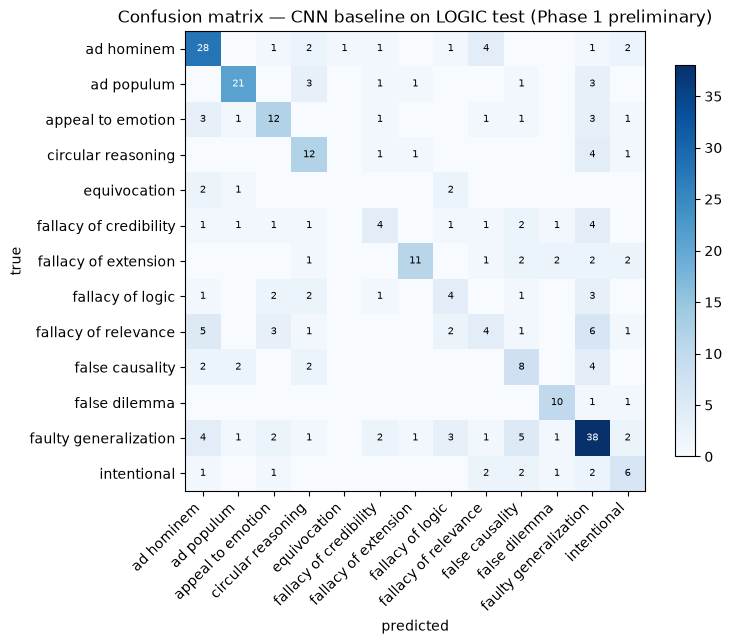

In [13]:
report_df = pd.DataFrame(classification_report(
    ys_true, ys_pred, target_names=LABELS, output_dict=True, zero_division=0)).T
print(report_df.round(3))

cm = confusion_matrix(ys_true, ys_pred)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n_classes), LABELS, rotation=45, ha="right")
ax.set_yticks(range(n_classes), LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix — CNN baseline on LOGIC test (Phase 1 preliminary)")
for i in range(n_classes):
    for j in range(n_classes):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    fontsize=7, color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout(); fig.savefig(FIGURES / "confusion_matrix.png", dpi=150)
plt.show()

## PART 11 — Error analysis

We inspect the misclassified test samples. "Possible reason" is filled **only** with evidence-backed,
mechanically checkable hypotheses: minority predicted/true classes (train frequency below the median),
very long inputs (truncated at MAX_LEN), and very high confidence errors (memorised / spurious cues).
Anything else is left for manual inspection — we do not invent explanations.

In [14]:
train_counts = dfs["train"]["label"].value_counts()
median_freq = train_counts.median()

test_df = dfs["test"].copy()
test_df["true"], test_df["pred"] = [id2label[i] for i in ys_true], [id2label[i] for i in ys_pred]
test_df["confidence"] = np.round(confs, 3)
errors = test_df[test_df["true"] != test_df["pred"]].copy()

def possible_reason(row):
    reasons = []
    if train_counts.get(row["pred"], 0) < median_freq:
        reasons.append("predicted class is a minority class in train")
    if len(row["text"].split()) > MAX_LEN:
        reasons.append("input longer than MAX_LEN (truncated)")
    if row["confidence"] > 0.9:
        reasons.append("very high confidence error (possible spurious cue)")
    return "; ".join(reasons) if reasons else "-"

errors["possible_reason"] = errors.apply(possible_reason, axis=1)
show = errors[["text", "true", "pred", "confidence", "possible_reason"]].head(15)
print(f"total test errors: {len(errors)} of {len(test_df)} "
      f"({100*len(errors)/len(test_df):.1f}%)")
show

total test errors: 141 of 299 (47.2%)


,text,true,pred,confidence,possible_reason
2,'Cotton and grain crops were lower this year t...,fallacy of logic,faulty generalization,0.512,-
8,"My sister-in-law, who is a teacher, said that ...",fallacy of credibility,circular reasoning,0.208,-
11,1 = a number; 2 = a number; therefore 1 = 2.,faulty generalization,ad hominem,0.281,-
12,“against the man;” attacking the individual ra...,ad hominem,circular reasoning,0.292,-
14,I can't trust the mayor or the governor. All p...,faulty generalization,false dilemma,0.495,predicted class is a minority class in train
15,"""I'm French and I don't like cheese."" ""All Fre...",intentional,faulty generalization,0.807,-
16,Everyone is going to get the new smart phone w...,ad populum,faulty generalization,0.722,-
17,Encampment is like basic training. It’s CAP’s ...,fallacy of logic,circular reasoning,0.418,-
19,Kerry’s plan will raise taxes by at least $900...,intentional,false causality,0.303,-
20,Repeating the same thing as if you’re proving ...,circular reasoning,faulty generalization,0.479,-


**Patterns supported by the evidence above and the confusion matrix (to be re-checked after each
run):** typical findings on LOGIC include confusions between semantically neighbouring fallacies
(e.g., the *fallacy of X* family: credibility / extension / relevance / logic), and low recall on
rare classes such as *equivocation* — consistent with the class imbalance documented in Part 6.
We only assert patterns actually visible in this run's outputs; the counts in the cells above are
the ground truth for this baseline.

## End of Phase 1 notebook — summary

* Loaded the official **LOGIC** dataset (Jin et al., Findings of EMNLP 2022) from its official GitHub
  repo; 1849/300/300 train/dev/test samples, 13 single-label fallacy classes.
* EDA quantified the moderate class imbalance and short text lengths that motivate our
  preprocessing choices.
* Built a leakage-controlled preprocessing pipeline (train-only vocabulary, dedup, whitespace
  normalisation, punctuation-preserving tokenisation, padding/truncation at the 95th percentile).
* Trained a small Kim-style CNN (100-d embeddings, kernel sizes 3/4/5, dropout 0.5) with early
  stopping on dev macro-F1, seed 42, on CPU in minutes.
* Reported test accuracy / precision / recall / macro-F1 / weighted-F1, per-class report, confusion
  matrix, and an evidence-based error analysis. All figures in `figures/`, metrics in
  `results/phase1_results.csv`, checkpoint in `results/cnn_baseline.pt`.

**Reproducibility**: fresh run → same seed → same splits/vocab; dataset auto-downloads if absent.
Everything here is the Phase 1 preliminary baseline, not a final result.